# Lab 7 — Four Ways to Predict the Next 5 Seconds

**AI for Mobility (CGN 6933) · Module 4 · reads with sections 4.8 (variational autoencoders) and 4.10 (diffusion basics)**

A car is 8 to 16 m before a stop line. You have watched it for 3 seconds. Where will it be
5 seconds from now?

You will answer that question four ways, **with the same data and the same encoder**:

- **A · Regression** — one past in, one future out.
- **B · Conditional VAE** — draw a few random numbers, then decode one future.
- **C · Translator** — write the future one "word" at a time, like an English → Spanish translator.
- **D · Diffusion** — start from noise and clean it up, a little at a time, into a future.

All four learn from the same (past, future) pairs and predict the same missing part. They differ
mainly in **the question each one is trained to answer** (their answering heads also differ in
size and shape; section 3 shows them). This lab measures what that difference buys you, and what
it costs.

| | |
|---|---|
| **What you build** | Four trajectory forecasters on one shared encoder design, and one scorecard for all of them |
| **What it proves** | Why a model trained with squared error predicts the *average* future, and how diffusion uses the same kind of loss to draw *real* futures |
| **Check it against** | The classical constant-velocity forecast, and a referee that knows what really happens next |
| **Runs on** | Colab (CPU is fine), macOS, Windows |
| **Needs** | `numpy`, `torch` 2.1 or newer, `matplotlib`. Nothing is downloaded, unless you choose the provided weights (3.6 MB). |
| **Time** | About 20 minutes to train all four on 2 CPU threads (less with more cores). With the provided weights, about 7 minutes for scoring and the step sweep. The optional stretch adds about 8. |

## Why the data are simulated

Real trajectory data (drone video, NGSIM, the Waymo Open Dataset) show each car's past once and
its future once. They cannot tell you what else that driver might have done. But to score a model
that draws *several* futures, you need the full set of futures that could follow the same past.
A simulator can give you that: re-run the same car from the same moment 200 times. That is why
this lab uses a simulated intersection. **Everything here is synthetic.** Section 11 says what
that costs you.

## 0 · Setup

One cell. On Colab everything is already installed.

`TRAIN_FROM_SCRATCH = False` loads `four_answers_weights.pt`, trained by exactly this code. If the
file is not next to this notebook, the cell downloads it from the course site. Use it if you are
short on time; train at least once yourself.

In [1]:
# %pip install --quiet numpy torch matplotlib
import math, os, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
TRAIN_FROM_SCRATCH = True
WEIGHTS = "four_answers_weights.pt"
WEIGHTS_URL = "https://ai4mobility.github.io/_static/data/four_answers_weights.pt"
if not TRAIN_FROM_SCRATCH and not os.path.exists(WEIGHTS):
    try:
        import urllib.request
        urllib.request.urlretrieve(WEIGHTS_URL, WEIGHTS); print("downloaded", WEIGHTS)
    except Exception as e:
        print(f"could not get {WEIGHTS} ({e}), so the models will be trained."); TRAIN_FROM_SCRATCH = True
STEPS = dict(reg=6000, cvae=6000, tok=6000, diff=6000)   # training steps per model
print("numpy", np.__version__, "| torch", torch.__version__, "| threads", torch.get_num_threads())

numpy 2.5.3 | torch 2.15.0+cpu | threads 2


## 1 · The intersection and its drivers

A four-leg intersection, one 3.6 m lane each way, curb returns of 3.6 m. Every car approaches
**northbound**. "Now" is the moment it is 8 to 16 m before the stop line, having braked gently to
its approach speed (5 to 12 m/s). The 3-second past is 16 points, one every 0.2 s. The 5-second
future is 25 points.

At "now", the driver decides: **left, straight or right**. The decision follows a **multinomial
logit** — the same model you use for mode choice:

| movement | utility |
|---|---|
| left | V = −0.3 + 3.0 · lane − 0.35 · (speed − 8) |
| straight | V = 0 |
| right | V = −0.4 − 3.0 · lane − 0.35 · (speed − 8) |

`lane` is how far left of the lane centre the car drives, in metres (about ±0.35 m is typical).
Cars that hug the left edge tend to turn left; slow cars tend to turn. Neither cue is certain. A
turn is off the menu if it would need braking harder than 4.5 m/s². After choosing, a left-turner
may stop to yield (40%), a right-turner less often (20%).

**The models never see this rule.** They see only trajectories, the way you would from a drone.

Run the next cell; skim it. You do not need to read the simulator line by line.

In [2]:
# A synthetic four-leg intersection. One lane each way, 3.6 m lanes, curb returns of 3.6 m.
# Every vehicle approaches northbound and then turns LEFT, goes STRAIGHT, or turns RIGHT.
# Units: metres and seconds. Origin = centre of the intersection. North = +y, east = +x.
import numpy as np

LANE = 3.6          # lane width = half the road width (one lane each way)
CURB_R = 3.6        # curb-return radius at the four corners
DT, REC = 0.05, 4   # simulate at 20 Hz, record every 4th step -> 5 Hz (0.2 s)
N_PAST, N_FUT = 16, 25          # 3 s of past (16 points incl. now), 5 s of future
MOVES = ["left", "straight", "right"]
CLASSES = ["left", "straight", "right", "not yet", "off-road"]


def _path(move, ds=0.05):
    """Centre line of one movement as a dense table: arc length s -> x, y, heading."""
    r = LANE * 1.5                                    # 5.4 m turning radius
    if move == "straight":
        y = np.arange(-120, 120 + ds, ds); x = np.full_like(y, LANE / 2)
        h = np.full_like(y, np.pi / 2); s_turn = 120 - LANE
    elif move == "left":                              # arc centre (-3.6, -3.6), 0 -> 90 deg
        y1 = np.arange(-120, -LANE, ds); x1 = np.full_like(y1, LANE / 2)
        th = np.arange(0, np.pi / 2, ds / r)
        x2 = -LANE + r * np.cos(th); y2 = -LANE + r * np.sin(th)
        x3 = np.arange(-LANE, -120 - ds, -ds); y3 = np.full_like(x3, LANE / 2)
        x = np.r_[x1, x2, x3]; y = np.r_[y1, y2, y3]
        h = np.r_[np.full_like(y1, np.pi / 2), th + np.pi / 2, np.full_like(x3, np.pi)]
        s_turn = 120 - LANE
    else:                                             # right: arc centre (7.2, -7.2), 180 -> 90 deg
        y1 = np.arange(-120, -2 * LANE, ds); x1 = np.full_like(y1, LANE / 2)
        th = np.arange(np.pi, np.pi / 2, -ds / r)
        x2 = 2 * LANE + r * np.cos(th); y2 = -2 * LANE + r * np.sin(th)
        x3 = np.arange(2 * LANE, 120 + ds, ds); y3 = np.full_like(x3, -LANE / 2)
        x = np.r_[x1, x2, x3]; y = np.r_[y1, y2, y3]
        h = np.r_[np.full_like(y1, np.pi / 2), th - np.pi / 2, np.zeros_like(x3)]
        s_turn = 120 - 2 * LANE
    s = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    s_end = s_turn + (0 if move == "straight" else r * np.pi / 2)
    return dict(s=s, x=x, y=y, h=h, s_turn=s_turn, s_end=s_end)


PATHS = {m: _path(m) for m in MOVES}
S_STOPLINE = 120 - LANE          # arc length of the stop line (y = -3.6) on every path


A_MAX = 4.5                      # hardest braking a driver will accept, m/s^2
LOGIT = dict(asc_left=-0.3, asc_right=-0.4, lane=3.0, speed=-0.35)   # the drivers' choice model


def approach(n, rng):
    """Everything you can SEE in the 3-s past. Each car cruises, then brakes gently to its approach
    speed, reaching it exactly 'now', D0 metres before the stop line. It holds its own lateral
    position in the lane (positive = toward the left edge)."""
    U = lambda a, b: rng.uniform(a, b, n)
    st = dict(v0=U(10, 14), v_a=U(5, 12), a_d=U(0.8, 2.5), D0=U(8, 16),
              lane=np.clip(rng.normal(0, 0.35, n), -0.9, 0.9))
    st["v0"] = np.maximum(st["v0"], st["v_a"])
    t = np.arange(-N_PAST + 1, 1) * 0.2                       # -3.0 ... 0 s
    T_d = (st["v0"] - st["v_a"]) / st["a_d"]                  # how long the braking lasted
    tt = np.maximum(t[None, :], -T_d[:, None])
    s_rel = st["v_a"][:, None] * tt - 0.5 * st["a_d"][:, None] * tt ** 2 \
        + st["v0"][:, None] * np.minimum(t[None, :] + T_d[:, None], 0)
    y = -LANE - st["D0"][:, None] + s_rel
    x = LANE / 2 - st["lane"][:, None] + 0 * y
    past = np.stack([x, y], -1).astype(np.float32)
    past += rng.normal(0, 0.02, past.shape).astype(np.float32)   # 2 cm tracking noise
    return st, past


def choice_probs(st):
    """The drivers' decision rule: a multinomial logit of lane position and approach speed. A turn
    the car cannot brake for (more than A_MAX) is not an option."""
    v, D0, lane = st["v_a"], st["D0"], st["lane"]
    ok_L = v ** 2 - 3.5 ** 2 <= 2 * A_MAX * D0
    ok_R = v ** 2 - 3.5 ** 2 <= 2 * A_MAX * (D0 - LANE)
    V = np.stack([LOGIT["asc_left"] + LOGIT["lane"] * lane + LOGIT["speed"] * (v - 8),
                  np.zeros_like(v),
                  LOGIT["asc_right"] - LOGIT["lane"] * lane + LOGIT["speed"] * (v - 8)], 1)
    V[:, 0] = np.where(ok_L, V[:, 0], -np.inf); V[:, 2] = np.where(ok_R, V[:, 2], -np.inf)
    e = np.exp(V - V.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)


def drive(st, rng):
    """What happens AFTER 'now': the driver picks a movement and drives it for 5 s."""
    n = len(st["v_a"])
    U = lambda a, b: rng.uniform(a, b, n)
    P = choice_probs(st)
    move = (rng.random(n)[:, None] > np.cumsum(P, 1)).sum(1).clip(0, 2)
    is_L, is_S, is_R = move == 0, move == 1, move == 2
    v_a, D0 = st["v_a"], st["D0"]
    dist = np.where(is_R, D0 - LANE, D0)                      # to where the curve starts
    can_stop = v_a ** 2 <= 2 * A_MAX * dist
    yields = can_stop & ((is_L & (rng.random(n) < 0.40)) | (is_R & (rng.random(n) < 0.20)))
    v_turn = np.where(is_L, U(3.5, 5.5), U(3.5, 5.0))
    v_goal = np.where(is_S, v_a, np.where(yields, 0.0, v_turn))
    wait = np.where(is_L, U(0.5, 2.5), U(0.5, 2.0)) * yields
    a_acc = U(1.0, 2.5)
    v_exit = np.where(is_S, np.maximum(v_a, U(10, 14)), U(9, 13))
    s0 = S_STOPLINE - D0
    s_goal = np.where(is_S, s0, np.array([PATHS[MOVES[m]]["s_turn"] for m in range(3)])[move])
    s_end = np.array([PATHS[MOVES[m]]["s_end"] for m in range(3)])[move]
    s_end = np.where(is_S, s0, s_end)                         # through cars may speed up at once
    s, v = s0.copy(), v_a.copy()
    phase = np.where(is_S, 2, 0); t_stop = np.zeros(n)
    rec = np.zeros((N_FUT, n))
    for k in range(N_FUT * REC):
        D = s_goal - s
        ap = phase == 0
        frac = np.clip(D / np.maximum(dist, 1e-6), 0, 1)
        v_ap = np.sqrt(v_goal ** 2 + (v_a ** 2 - v_goal ** 2) * frac)
        v = np.where(ap, v_ap, v)
        v = np.where(ap & (v_goal == 0), np.maximum(v, np.minimum(0.3, D / DT)), v)  # creep to the line
        stop_now = ap & (v_goal == 0) & (D <= 0.05)
        pass_now = ap & (v_goal > 0) & (D <= 0)
        phase = np.where(stop_now, 1, np.where(pass_now, 2, phase))
        t_stop = np.where(stop_now, k * DT, t_stop)
        phase = np.where((phase == 1) & (k * DT - t_stop >= wait), 2, phase)
        gp = phase == 2
        cap = np.where(s < s_end, v_turn, v_exit)
        v = np.where(gp, np.minimum(v + a_acc * DT, cap), v)
        v = np.where(phase == 1, 0.0, v)
        s = s + v * DT
        if k % REC == REC - 1:
            rec[k // REC] = s
    S = rec.T
    fut = np.zeros((n, N_FUT, 2), np.float32)
    for m in range(3):
        Pm = PATHS[MOVES[m]]; sel = move == m
        Ssel = S[sel]
        x = np.interp(Ssel, Pm["s"], Pm["x"]); y = np.interp(Ssel, Pm["s"], Pm["y"])
        h = np.interp(Ssel, Pm["s"], Pm["h"])
        taper = np.clip(1 - (Ssel - Pm["s_turn"]) / 10.0, 0, 1)    # lane position fades over 10 m
        d = st["lane"][sel][:, None] * np.where(Ssel < Pm["s_turn"], 1.0, taper)
        fut[sel, :, 0] = x - d * np.sin(h); fut[sel, :, 1] = y + d * np.cos(h)
    fut += rng.normal(0, 0.02, fut.shape).astype(np.float32)
    return move, fut, dict(yields=yields, probs=P.astype(np.float32))


def simulate(n, seed):
    """n cars: past (n,16,2), future (n,25,2), movement (n,), extras (incl. the hidden state)."""
    rng = np.random.default_rng(seed)
    st, past = approach(n, rng)
    move, fut, ex = drive(st, rng)
    ex["state"] = st
    return past, fut, move, ex


def resimulate(st, k, seed):
    """Same 'now', k fresh futures for each car: (n, k, 25, 2). This is the referee."""
    rng = np.random.default_rng(seed)
    big = {key: np.repeat(v, k) for key, v in st.items()}
    _, fut, _ = drive(big, rng)
    return fut.reshape(len(st["v_a"]), k, N_FUT, 2)


def offroad_depth(x, y):
    """How far (m) a point sits outside the pavement; 0 on the road."""
    ax, ay = np.abs(x) - LANE, np.abs(y) - LANE
    corner = (ax > 0) & (ay > 0)
    r = np.hypot(ax - CURB_R, ay - CURB_R)
    in_sq = (ax <= CURB_R) & (ay <= CURB_R)
    depth = np.where(in_sq, np.where(r >= CURB_R, 0.0, np.minimum(np.minimum(ax, ay), CURB_R - r)),
                     np.minimum(ax, ay))
    return np.where(corner, depth, 0.0)


def classify(fut, tol=0.25):
    """Label each future by where it is after 5 s: 0 left (at least 1 m west of the centre line),
    1 straight (through the box), 2 right (past the east curb line), 3 not yet (still on the
    approach or just entering), 4 off-road (any point more than 25 cm off the pavement)."""
    fut = np.asarray(fut)
    off = (offroad_depth(fut[..., 0], fut[..., 1]) > tol).any(-1)
    xf, yf = fut[..., -1, 0], fut[..., -1, 1]
    c = np.full(xf.shape, 3)
    c = np.where(xf < -1.0, 0, c)
    c = np.where((yf > LANE) & (np.abs(xf) <= LANE), 1, c)
    c = np.where(xf > LANE, 2, c)
    return np.where(off, 4, c)

In [3]:
def draw_intersection(ax, lim=30, color="#E9E6DA", edge="#9A9580"):
    """Pavement drawing for figures: two strips plus the four curb returns."""
    import matplotlib.patches as mp
    ax.add_patch(mp.Rectangle((-LANE, -lim), 2 * LANE, 2 * lim, fc=color, ec="none", zorder=0))
    ax.add_patch(mp.Rectangle((-lim, -LANE), 2 * lim, 2 * LANE, fc=color, ec="none", zorder=0))
    for sx in (-1, 1):
        for sy in (-1, 1):
            cx, cy = sx * (LANE + CURB_R), sy * (LANE + CURB_R)
            sq = mp.Rectangle((min(sx * LANE, cx), min(sy * LANE, cy)), CURB_R, CURB_R,
                              fc=color, ec="none", zorder=0)
            ax.add_patch(sq)
            ax.add_patch(mp.Circle((cx, cy), CURB_R, fc="white", ec="none", zorder=0.5))
    for v in (-1, 1):
        ax.plot([0, 0], [v * LANE, v * lim], color="#C9B458", lw=0.8, ls=(0, (4, 4)), zorder=0.6)
        ax.plot([v * LANE, v * lim], [0, 0], color="#C9B458", lw=0.8, ls=(0, (4, 4)), zorder=0.6)
    ax.plot([0, LANE], [-LANE, -LANE], color="white", lw=2.5, zorder=0.6)   # stop line
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)

GREEN, DKGREEN, GOLD, SAND, RUST, GRAY, RED = "#006747", "#003E2A", "#B79F4D", "#CFC493", "#B5581E", "#6B7280", "#C0392B"
CLASS_COLOR = [GREEN, GOLD, RUST, GRAY, RED]          # left, straight, right, not yet, off-road
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def plot_paths(ax, futs, past=None, lim=30, alpha=0.35, lw=1.0, color_by_class=True, color=None):
    """Draw futures (k, 25, 2) on the intersection, coloured by where they end up."""
    draw_intersection(ax, lim)
    futs = np.asarray(futs)
    cls = classify(futs)
    for f, c in zip(futs, cls):
        ax.plot(f[:, 0], f[:, 1], color=CLASS_COLOR[c] if color_by_class else color,
                lw=lw, alpha=alpha, solid_capstyle="round", zorder=2)
    if past is not None:
        ax.plot(past[:, 0], past[:, 1], color="black", lw=2.2, zorder=3)
        ax.plot(*past[-1], "o", color="black", ms=4, zorder=4)
    return cls

def share_text(cls, per_line=3):
    parts = [f"{CLASSES[j]} {100 * np.mean(cls == j):.0f}%" for j in range(len(CLASSES)) if np.any(cls == j)]
    return "\n".join(" · ".join(parts[i:i + per_line]) for i in range(0, len(parts), per_line))

def legend_classes(fig, y=0.0):
    hs = [plt.Line2D([], [], color=c, lw=2) for c in CLASS_COLOR] + [plt.Line2D([], [], color="black", lw=2.2)]
    fig.legend(hs, CLASSES + ["past 3 s"], loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, y))

def pick_cases(ref, at_least=0.25):
    """Three test pasts where the referee splits between two movements (left/right, left/straight,
    straight/right): for each pair, the FIRST test car where both are at least 25% likely. A neutral
    rule, so the examples are not chosen by how well any model does on them."""
    return [int(np.argmax(np.minimum(ref[:, a], ref[:, b]) >= at_least)) for a, b in [(0, 2), (0, 1), (1, 2)]]

def show_answers(title, futs_by_case, pasts, real_by_case):
    """Top row: what really happens (50 re-runs). Bottom row: the model's answer(s). One column per past."""
    fig, axs = plt.subplots(2, len(pasts), figsize=(4 * len(pasts), 8.2))
    for j, (past, futs, real) in enumerate(zip(pasts, futs_by_case, real_by_case)):
        cl = plot_paths(axs[0, j], real[:50], past, lim=24, alpha=0.35)
        axs[0, j].set_title("What really happens\n" + share_text(cl), fontsize=9)
        one = len(futs) == 1
        cl = plot_paths(axs[1, j], futs, past, lim=24, alpha=1.0 if one else 0.35, lw=2.4 if one else 1.0)
        axs[1, j].set_title(title + "\n" + (CLASSES[cl[0]] if one else share_text(cl)), fontsize=9)
    legend_classes(fig, 0.0)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

Now make the data: 20,000 training cars, 1,000 validation cars, 1,000 test cars, each from
its own random seed, so no test car was ever seen in training.

training cars by movement: {'left': '29%', 'straight': '50%', 'right': '21%'}
where they are after 5 s:  {'left': '18%', 'straight': '50%', 'right': '18%', 'not yet': '14%', 'off-road': '0%'}


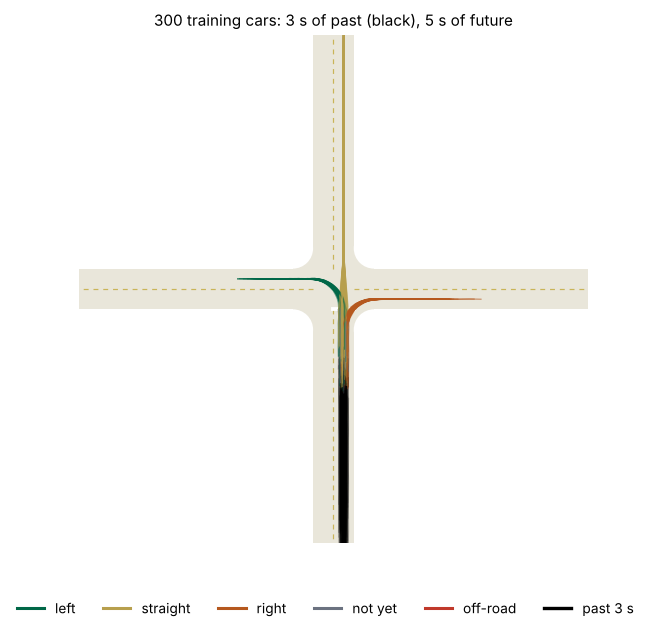

In [4]:
D = {}
for split, n_cars, seed in [("train", 20000, 1), ("val", 1000, 2), ("test", 1000, 3)]:
    past, fut, move, ex = simulate(n_cars, seed)
    D[split] = dict(past=past, fut=fut, move=move, state=ex["state"])
tr, te = D["train"], D["test"]
print("training cars by movement:", {m: f"{np.mean(tr['move'] == j):.0%}" for j, m in enumerate(MOVES)})
print("where they are after 5 s: ", {c: f"{np.mean(classify(tr['fut']) == j):.0%}" for j, c in enumerate(CLASSES)})

fig, ax = plt.subplots(figsize=(6, 6))
draw_intersection(ax, 45)
cls = classify(tr["fut"][:300])
for i in range(300):
    ax.plot(*tr["past"][i].T, color="black", lw=0.5, alpha=0.25)
    ax.plot(*tr["fut"][i].T, color=CLASS_COLOR[cls[i]], lw=0.8, alpha=0.6)
ax.set_title("300 training cars: 3 s of past (black), 5 s of future")
legend_classes(fig, -0.02); plt.show()

**Check:** about 29% of cars turn left, 50% go straight and
21% turn right. After 5 s, 14% are "not yet" through: mostly left-turners
still waiting to yield. No real car leaves the pavement.

## 2 · Same past, different futures

For every validation and test car, the **referee** re-runs the simulator 200 times from the
same moment — same position, same speed, same lane position — and records where each re-run ends
up. That gives the true mix of futures for that past. A second, independent set of 20 re-runs
plays a **perfect model**: no model can beat its score, so it shows you the floor.

How ambiguous is the test set? For 73% of test cars, no outcome is more than 80% likely.
For 59%, none is more than 60% likely.

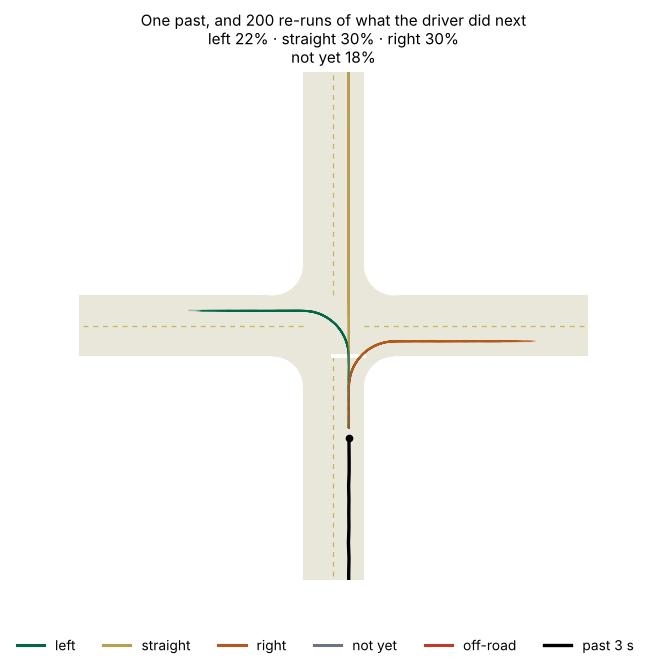

In [5]:
def class_shares(futs):
    """futs: (B, k, 25, 2) in metres -> share of the k futures in each of the 5 classes."""
    c = classify(futs)
    return np.stack([(c == j).mean(1) for j in range(len(CLASSES))], 1)

def scorecard(samples, fut_true, ref_shares):
    """samples: (B, k, 25, 2) metres. Returns the four numbers every model is judged on."""
    sh = class_shares(samples)
    err = np.linalg.norm(samples - fut_true[:, None], axis=-1).mean(-1)      # (B, k) mean metres off
    return dict(
        offroad=float((classify(samples) == 4).mean()),
        mix_error=float(0.5 * np.abs(sh - ref_shares).sum(1).mean()),
        ade_one=float(err[:, 0].mean()),
        min_ade6=float(err[:, :6].min(1).mean()),
    )

REF = {}
for split, seed in [("test", 11), ("val", 21)]:
    st = D[split]["state"]
    REF[split] = dict(ref=class_shares(resimulate(st, 200, seed)), oracle=resimulate(st, 20, seed + 1))
ref = REF["test"]["ref"]
CASES = pick_cases(ref)                                   # three pasts where the referee is split
case_state = {k: v[CASES] for k, v in te["state"].items()}
REAL = resimulate(case_state, 200, 99)                    # 200 re-runs for each of the three

fig, ax = plt.subplots(figsize=(6, 6))
cl = plot_paths(ax, REAL[0], te["past"][CASES[0]], lim=30, alpha=0.3)
ax.set_title("One past, and 200 re-runs of what the driver did next\n" + share_text(cl))
legend_classes(fig, -0.02); plt.show()

**Stop and decide before you read on.** If you could draw only *one* path for this car,
which path would you draw? Write it down. You will meet your answer again in section 5.

### How every model is scored

Every model draws **20 futures** for each of the 1,000 test pasts (a model that cannot vary just
repeats its one answer), and gets four numbers. Lower is better for all four.

1. **Off-road** — the share of drawn futures with any point more than 25 cm off the pavement.
   Real cars: 0%.
2. **Maneuver-mix error** — sort the 20 futures into left / straight / right / not yet / off-road,
   and compare those shares with the referee's: add up how far off each share is, then halve
   it. 0 means the same mix, 1 means no overlap at all. Example: a model that draws 50% left and
   50% straight where the referee says 30% and 70% scores 0.20. Even the perfect model scores
   about 0.11, because 20 draws are a small sample.
3. **Best of 6** — take 6 of the futures; how far is the *closest* one from what this car actually
   did? The average miss over the 25 points, in metres. This is minADE₆, the standard
   trajectory-prediction score.
4. **One draw** — how far one drawn future is from what the car actually did (ADE).

Watch number 4. It rewards one particular kind of answer. By the end you will know which, and
why the field stopped using it alone.

In [6]:
RESULTS = {"Perfect model": scorecard(REF["test"]["oracle"], te["fut"], ref)}
def report(name, samples):
    RESULTS[name] = scorecard(samples, te["fut"], ref)
    r = RESULTS[name]
    print(f"{name:16s}  off-road {100 * r['offroad']:5.1f}%   mix error {r['mix_error']:.3f}   "
          f"best of 6 {r['min_ade6']:5.2f} m   one draw {r['ade_one']:5.2f} m")
report("Perfect model", REF["test"]["oracle"])

Perfect model     off-road   0.0%   mix error 0.111   best of 6  1.51 m   one draw  6.53 m


## 3 · One past encoder, four ways to answer

Here is the whole lab in one picture. Read it from left to right: the past goes into an encoder,
and the encoder's output goes to one of four answering heads.

![FA_Structure_0_Overview.png](https://ai4mobility.github.io/_static/figures/FA_Structure_0_Overview.png)

The **past encoder** is the same design in all four models (each model trains its own copy).
Each of the 16 past points becomes a token of 4 numbers — where the car is and how fast it moves —
and a small transformer (the one from Module 2) mixes them into 16 context tokens of 64 numbers.
`H` is all 16 tokens; `h` is the token for "now". The heads use `h` (A, B) or all of `H` through
cross-attention (C, D).

Every model predicts the same target: the future measured from "now", in units of 10 m.

In [7]:
SCALE = 10.0                       # networks see metres / 10
ORIGIN = np.array([LANE / 2, -20.0], np.float32)

def past_features(past):
    """Each past point becomes a token of 4 numbers: where the car is and how it is moving."""
    vel = np.diff(past, axis=1, prepend=past[:, :1]) / 0.2          # m/s
    vel[:, 0] = vel[:, 1]
    f = np.concatenate([(past - ORIGIN) / SCALE, vel / SCALE], -1)
    return torch.tensor(f, dtype=torch.float32)

def to_rel(past, fut):      # target for every model: the future, measured from "now", in 10 m units
    return torch.tensor((fut - past[:, -1:]) / SCALE, dtype=torch.float32)

def from_rel(past, rel):    # back to metres on the map; rel is (B, k, 25, 2)
    return rel * SCALE + past[:, None, -1:, :]

class PastEncoder(nn.Module):
    """Same design in all four models: 16 past tokens -> a small transformer -> 16 context tokens.
    H = all 16 tokens (for cross-attention); h = the token for 'now' (a single summary vector)."""
    def __init__(self, d=64, layers=2, heads=4):
        super().__init__()
        self.inp = nn.Linear(4, d)
        self.pos = nn.Parameter(0.02 * torch.randn(N_PAST, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)

    def forward(self, pf):
        H = self.norm(self.tf(self.inp(pf) + self.pos))
        return H, H[:, -1]

def mlp(i, o, w=256, depth=2):
    L, d = [], i
    for _ in range(depth):
        L += [nn.Linear(d, w), nn.GELU()]; d = w
    return nn.Sequential(*L, nn.Linear(d, o))

def train(model, pf, target, steps, batch=256, lr=2e-3, seed=0, log_every=0):
    """AdamW with a one-cycle learning-rate schedule, random batches of 256 cars. Returns the seconds it took."""
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    g = torch.Generator().manual_seed(seed)
    t0, run = time.time(), 0.0
    model.train()
    for it in range(steps):
        idx = torch.randint(0, pf.shape[0], (batch,), generator=g)
        loss = model.loss(pf[idx], target[idx])
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        run = 0.98 * run + 0.02 * loss.item() if it else loss.item()
        if log_every and (it + 1) % log_every == 0:
            print(f"  step {it + 1:5d}   loss {run:.4f}   {time.time() - t0:5.0f} s")
    model.eval()
    return time.time() - t0

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def draw(name, m, past, k, seed=0, **kw):
    """k futures in metres for every past, plus milliseconds per 1,000 futures and passes per future."""
    pf = past_features(past)
    torch.manual_seed(seed)
    t0 = time.time()
    if name == "tok":
        out = detokenize(past, m.sample(pf, k).numpy())
    else:
        out = from_rel(past, m.sample(pf, k, **kw).numpy())
    ms = (time.time() - t0) / (len(past) * k) * 1e6
    passes = dict(reg=1, cvae=1, tok=N_FUT).get(name, kw.get("steps", 25))
    return out.astype(np.float32), ms, passes

pf_train = past_features(tr["past"]); rel_train = to_rel(tr["past"], tr["fut"])
SAVED = torch.load(WEIGHTS) if not TRAIN_FROM_SCRATCH else {}
def fit(name, make, target):
    torch.manual_seed(0)                      # same starting weights as the run that built this lab
    model = make()
    if TRAIN_FROM_SCRATCH:
        secs = train(model, pf_train, target, STEPS[name], log_every=1000)
        print(f"trained in {secs:.0f} s, {n_params(model):,} weights")
    else:
        model.load_state_dict(SAVED[name]); model.eval(); print("loaded", name)
    return model

## 4 · Baseline first: constant velocity

The classical forecast: keep the current velocity for 5 seconds. No training, one answer.

In [8]:
def const_velocity(past):
    """The classical baseline: keep the current velocity for 5 s. One answer, (B, 1, 25, 2).
    Velocity = average over the last 0.6 s, which smooths the 2 cm tracking noise."""
    v = (past[:, -1] - past[:, -4]) / 3
    k = np.arange(1, N_FUT + 1)[None, :, None]
    return (past[:, -1:, :] + k * v[:, None, :])[:, None]

cv = const_velocity(te["past"])
report("Constant velocity", np.repeat(cv, 20, 1))

Constant velocity  off-road   0.0%   mix error 0.505   best of 6  6.59 m   one draw  6.59 m


Constant velocity never turns and never slows down, so every turning or yielding car is a
miss: mix error 0.50, one-draw miss 6.6 m. Any learned model must beat this.

## 5 · A · Regression: one past, one future

![FA_Structure_A_Regression.png](https://ai4mobility.github.io/_static/figures/FA_Structure_A_Regression.png)


**The key equation.** Train the network f so that, over the training pairs,

$$\text{average of }\ \lVert x - f(c) \rVert^2 \ \text{is as small as possible.}$$

| symbol | meaning here |
|---|---|
| c | the past: 16 points of position and velocity (x, y, vx, vy) |
| x | the true future: 25 points of (x, y), measured from "now" |
| f(c) | the network's one predicted future |

**In words:** the best possible f(c) is the *average* of every future that followed pasts like c.
That is a theorem about squared error, not a property of this network. You met it in section 4.8
("the decoder returns an average") and in regression class (the fitted value is a conditional
mean).

In [9]:
class Regression(nn.Module):
    """A. Past -> one future. Loss: squared error. Learns the AVERAGE future for this past."""
    def __init__(self, d=64):
        super().__init__()
        self.enc, self.head = PastEncoder(d), mlp(d, N_FUT * 2)

    def forward(self, pf):
        return self.head(self.enc(pf)[1]).view(-1, N_FUT, 2)

    def loss(self, pf, rel):
        return F.mse_loss(self(pf), rel)

    @torch.no_grad()
    def sample(self, pf, k):        # no randomness anywhere: k "samples" are k copies
        return self(pf)[:, None].expand(-1, k, -1, -1)

reg = fit("reg", Regression, rel_train)
DRAWN = {}
DRAWN["A Regression"] = draw("reg", reg, te["past"], 20)[0]
report("A Regression", DRAWN["A Regression"])

  step  1000   loss 0.3847      22 s


  step  2000   loss 0.3756      43 s


  step  3000   loss 0.3762      68 s


  step  4000   loss 0.3703      99 s


  step  5000   loss 0.3687     124 s


  step  6000   loss 0.3628     157 s
trained in 157 s, 163,698 weights
A Regression      off-road  22.5%   mix error 0.532   best of 6  5.48 m   one draw  5.48 m


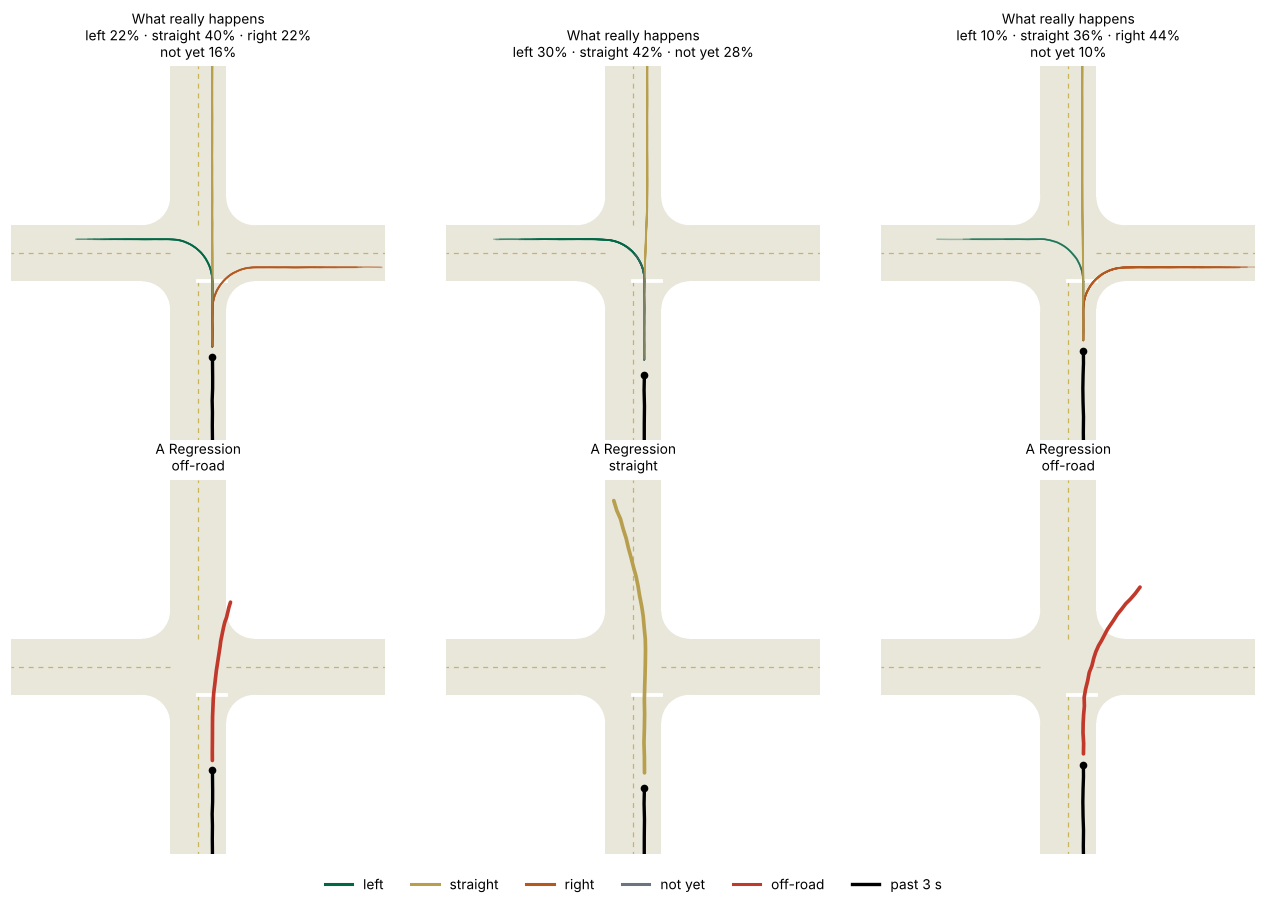

In [10]:
def look(title, name, model, **kw):
    pasts = te["past"][CASES]
    futs = [draw(name, model, pasts[j:j + 1], 1 if name == "reg" else 50, seed=j, **kw)[0][0] for j in range(3)]
    show_answers(title, futs, pasts, REAL)

look("A Regression", "reg", reg)

**Compare with the path you wrote down in section 2.** Regression gives one path per past. In
the first and third columns that path heads for the corner between two branches and leaves the
pavement; in the second it drives straight while leaning toward the left turn it has averaged in.
Over the whole test set, **22.5% of regression's futures leave the pavement**, and its mix error
(0.53) is no better than constant velocity's (0.50).

Now read its last number. Regression's one-draw miss, 5.5 m, is the **best of any model, better
even than the perfect model's 6.5 m**. That is not a bug. The average path sits in the
middle of all the possible futures, so it is never very far from any of them. A score that
averages one draw's distance from the truth rewards that, even when the middle is a path no car
can drive. This is why trajectory papers report best-of-K (minADE₆) next to ADE, and why this lab
also counts off-road futures and the maneuver mix.

## 6 · B · Conditional VAE: a dice roll, then a decoder

![FA_Structure_B_CVAE.png](https://ai4mobility.github.io/_static/figures/FA_Structure_B_CVAE.png)


The VAE of section 4.8, given the past as a condition. During training, a **posterior net**
looks at the true future and picks a code z of 4 numbers; the decoder must rebuild the future
from (past, z). A **prior net** learns to guess z from the past alone. To generate, draw z from
the prior and decode.

**The key equation:**

$$\text{loss} = \frac{\lVert x - \text{dec}(c, z) \rVert^2}{2\sigma^2} + \text{KL}\big(q(z \mid c, x)\ \Vert\ p(z \mid c)\big)$$

| symbol | meaning here |
|---|---|
| z | 4 random numbers that choose *which* future |
| q(z ∣ c, x) | the posterior net: z chosen by someone who has seen the answer |
| p(z ∣ c) | the prior net: z guessed from the past alone |
| σ | a dial: 1 here (in the model's units of 10 m). With a large σ the model cares less about matching each future exactly and more about keeping z simple. It was chosen on the validation cars (table below). |

**In words:** the first term is still squared error. The second keeps the posterior's z close to
what the prior can produce, so that drawing from the prior gives futures the decoder knows how to
decode.

  step  1000   loss 0.0329      30 s


  step  2000   loss 0.0310      57 s


  step  3000   loss 0.0306      82 s


  step  4000   loss 0.0294     109 s


  step  5000   loss 0.0290     134 s


  step  6000   loss 0.0289     159 s
trained in 159 s, 346,498 weights
B Cond. VAE       off-road   2.3%   mix error 0.143   best of 6  1.70 m   one draw  6.09 m


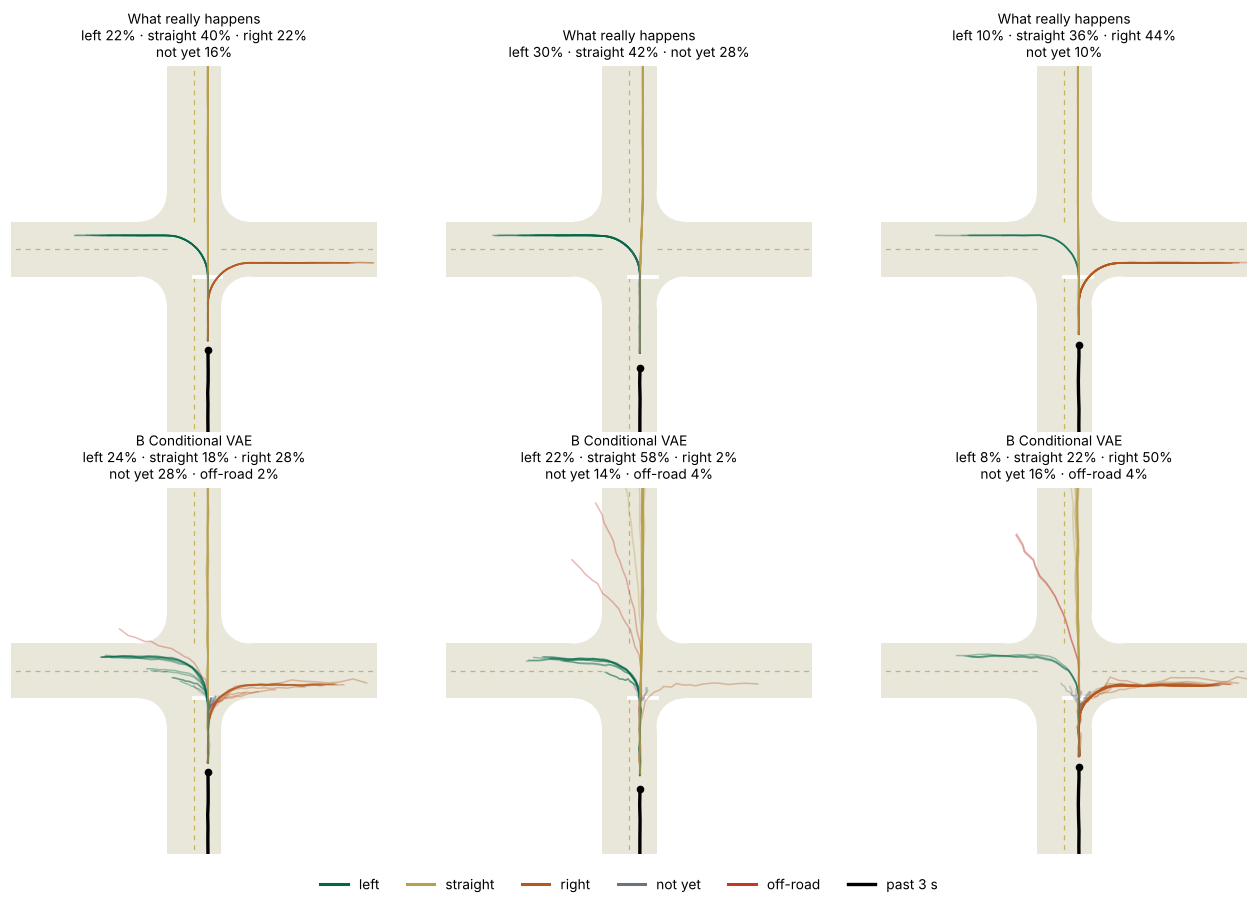

In [11]:
class CVAE(nn.Module):
    """B. Conditional VAE. A few random numbers z, drawn ONCE, choose which future to draw.
    Training: an encoder peeks at the true future to set z; a prior learns to guess z from the past."""
    def __init__(self, d=64, zdim=4, sigma=1.0):
        super().__init__()
        self.enc, self.zdim, self.sigma = PastEncoder(d), zdim, sigma
        self.post = mlp(d + N_FUT * 2, 2 * zdim)        # q(z | past, future)  - training only
        self.prior = mlp(d, 2 * zdim)                   # p(z | past)          - used to generate
        self.dec = mlp(d + zdim, N_FUT * 2)             # future = dec(past, z)

    def loss(self, pf, rel):
        h = self.enc(pf)[1]
        mq, lq = self.post(torch.cat([h, rel.flatten(1)], 1)).chunk(2, 1)
        mp, lp = self.prior(h).chunk(2, 1)
        z = mq + torch.randn_like(mq) * (0.5 * lq).exp()
        rec = self.dec(torch.cat([h, z], 1)).view(-1, N_FUT, 2)
        recon = ((rec - rel) ** 2).sum((1, 2)) / (2 * self.sigma ** 2)
        kl = 0.5 * (lp - lq + (lq.exp() + (mq - mp) ** 2) / lp.exp() - 1).sum(1)
        return (recon + kl).mean() / (N_FUT * 2)

    @torch.no_grad()
    def sample(self, pf, k):
        h = self.enc(pf)[1]
        mp, lp = self.prior(h).chunk(2, 1)
        h, mp, lp = (t.repeat_interleave(k, 0) for t in (h, mp, lp))
        z = mp + torch.randn_like(mp) * (0.5 * lp).exp()
        return self.dec(torch.cat([h, z], 1)).view(-1, k, N_FUT, 2)

cvae = fit("cvae", lambda: CVAE(sigma=1.0), rel_train)
DRAWN["B Cond. VAE"] = draw("cvae", cvae, te["past"], 20)[0]
report("B Cond. VAE", DRAWN["B Cond. VAE"])
look("B Conditional VAE", "cvae", cvae)

The VAE draws real variety: its mix error falls to 0.14, from regression's 0.53. Look at the
borders between branches, though: a few draws cut the corner between the left turn and straight
ahead, and 2.3% of all its futures leave the pavement, about 10 times diffusion's rate
(section 10). The 4 numbers in z choose the future in one shot; when a draw of z falls between
two groups, the decoder still returns something in between.

Its one setting, σ, matters a lot. It was chosen on the **validation** cars, never the test cars,
by the lowest mix error. This table comes from the tuning run (`four_answers/fa_tune.py`: five
trainings, about 12 minutes), not from this notebook:

| σ (× 10 m) | off-road | mix error | best of 6 | one draw |
|---|---|---|---|---|
| 0.03 | 17.2% | 0.255 | 2.33 m | 6.74 m |
| 0.1 | 9.1% | 0.183 | 1.77 m | 6.47 m |
| 0.3 | 3.4% | 0.152 | 1.56 m | 6.42 m |
| 1 | 2.7% | 0.145 | 1.67 m | 6.17 m |
| 3 | 5.1% | 0.242 | 2.27 m | 5.75 m |

This likely matches the two failure modes of sections 4.4 and 4.8: holes in the latent space, and blur. With σ small, the model packs every
detail into z; the prior cannot learn where those z values sit, so many draws decode into odd
paths (17% off-road at σ = 0.03). With σ large, the decoder can ignore z and slide back toward the
average: at σ = 3 its one-draw miss drops toward regression's, the sign of averaging.

## 7 · C · Translator: write the future word by word

![FA_Structure_C_Translator.png](https://ai4mobility.github.io/_static/figures/FA_Structure_C_Translator.png)


This is the English → Spanish idea taken literally. The past is the source sentence. The future
is a sentence of 25 **words**, one per 0.2 s, and a word is the car's acceleration in that 0.2 s,
rounded to a 13 × 13 menu (steps of 1.5 m/s²). The decoder writes one word at a time, looking back
at the words it has written and across at the past (cross-attention, Module 2).

**The key equation:**

$$\text{loss} = -\sum_{k=1}^{25} \log p(w_k \mid w_1, \dots, w_{k-1},\ c)$$

**In words:** for each word, the model puts a probability on every item of the menu; the loss
punishes it for putting little probability on the word that really came next. A menu can keep
several answers at once ("left 40%, right 35%"), which squared error cannot.

**First check the rounding.** If the words were too coarse, the translator would lose before it
starts.

In [12]:
NB, STEP = 13, 0.06            # 13 bins per axis, 0.06 m per (0.2 s)^2  = 1.5 m/s^2 per bin
VOCAB, BOS = NB * NB, NB * NB  # 169 "words", plus a start-of-sentence token

def tokenize(past, fut):
    """Turn each future into 25 words. A word = the acceleration (x and y) for the next 0.2 s,
    rounded to one of 13 x 13 values. Closed loop: each word aims at the true point from where
    the ROUNDED path has got to, so rounding errors do not pile up."""
    p, v = past[:, -1].copy(), past[:, -1] - past[:, -2]
    toks, path = [], []
    for k in range(N_FUT):
        a = fut[:, k] - p - v
        ia = np.clip(np.round(a / STEP) + NB // 2, 0, NB - 1).astype(int)
        v = v + (ia - NB // 2) * STEP; p = p + v
        toks.append(ia[:, 0] * NB + ia[:, 1]); path.append(p.copy())
    return np.stack(toks, 1), np.stack(path, 1)

def detokenize(past, toks):
    """Words back to a path (metres). toks: (B, k, 25)."""
    ia = np.stack([toks // NB, toks % NB], -1) - NB // 2
    v0 = (past[:, -1] - past[:, -2])[:, None, None]
    v = v0 + np.cumsum(ia * STEP, axis=2)
    return past[:, None, -1:] + np.cumsum(v, axis=2)

class Translator(nn.Module):
    """C. A sentence translator: the past is the 'English' sentence, the future is written as
    25 'Spanish' words, one at a time. Loss: cross-entropy over a menu of 169 words."""
    def __init__(self, d=64, layers=2, heads=4):
        super().__init__()
        self.enc = PastEncoder(d)
        self.emb = nn.Embedding(VOCAB + 1, d)
        self.pos = nn.Parameter(0.02 * torch.randn(N_FUT, d))
        layer = nn.TransformerDecoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.dec = nn.TransformerDecoder(layer, layers)
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, VOCAB))
        self.register_buffer("mask", nn.Transformer.generate_square_subsequent_mask(N_FUT))

    def logits(self, H, prev):              # prev: (B, L) words written so far, starting with BOS
        L = prev.shape[1]
        x = self.emb(prev) + self.pos[:L]
        return self.out(self.dec(x, H, tgt_mask=self.mask[:L, :L], tgt_is_causal=True))

    def loss(self, pf, toks):
        H, _ = self.enc(pf)
        prev = torch.cat([torch.full_like(toks[:, :1], BOS), toks[:, :-1]], 1)
        return F.cross_entropy(self.logits(H, prev).reshape(-1, VOCAB), toks.reshape(-1))

    @torch.no_grad()
    def sample(self, pf, k, temperature=1.0):
        H, _ = self.enc(pf)
        H = H.repeat_interleave(k, 0)
        prev = torch.full((H.shape[0], 1), BOS, dtype=torch.long)
        for _ in range(N_FUT):                 # 25 passes: one word per pass
            p = F.softmax(self.logits(H, prev)[:, -1] / temperature, -1)
            prev = torch.cat([prev, torch.multinomial(p, 1)], 1)
        return prev[:, 1:].view(-1, k, N_FUT)

tok_train, rounded = tokenize(tr["past"], tr["fut"])
err = np.linalg.norm(rounded - tr["fut"], axis=-1)
print(f"rounding error: typical {np.sqrt((err ** 2).mean()):.3f} m, worst {err.max():.3f} m")

rounding error: typical 0.024 m, worst 0.063 m


The rounding costs about 0.024 m (worst case about 0.06 m on one axis): far below anything that
matters here. The *closed loop* in `tokenize` is the trick. Each word is chosen from where the
rounded path really is, so each step fixes the last step's rounding, and errors do not add up.

  step  1000   loss 2.4176      79 s


  step  2000   loss 2.1879     157 s


  step  3000   loss 2.0697     233 s


  step  4000   loss 1.9897     306 s


  step  5000   loss 1.9420     383 s


  step  6000   loss 1.9231     458 s
trained in 458 s, 192,489 weights


C Translator      off-road   0.8%   mix error 0.164   best of 6  1.67 m   one draw  7.11 m


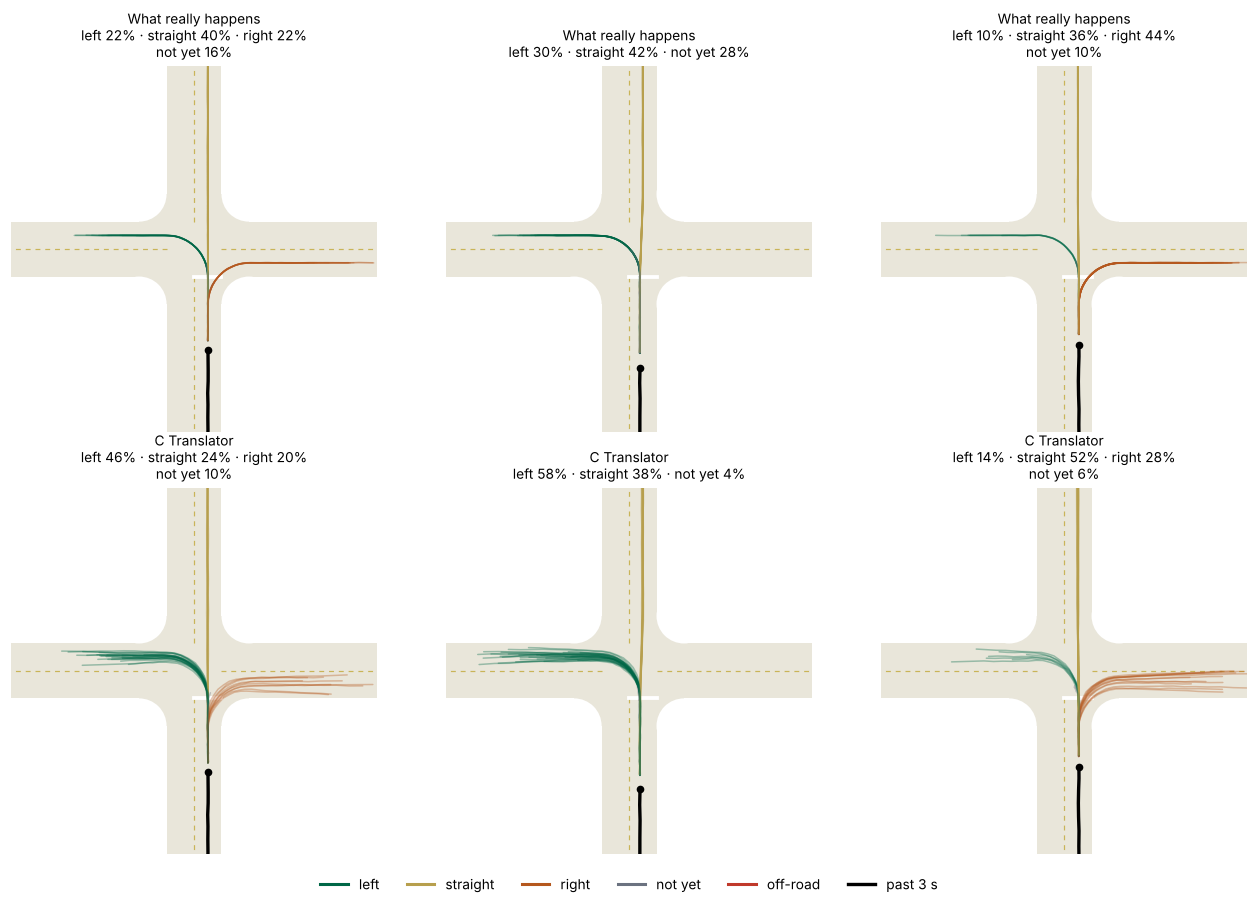

In [13]:
tok = fit("tok", Translator, torch.tensor(tok_train))
DRAWN["C Translator"] = draw("tok", tok, te["past"], 20)[0]
report("C Translator", DRAWN["C Translator"])
look("C Translator", "tok", tok)

The translator keeps the branches apart: only 0.8% of its futures leave the pavement, and its
mix error is 0.16. A menu of words can say "left 40%, right 35%" at once, which squared error
cannot. Two prices show up. It needed a tokenizer, an extra design step (cheap here, because
rounding costs about 2 cm). And it writes the future in a fixed order, one pass per word:
1.9 s per 1,000 futures in the run that built this lab, against 2 ms for regression. (This
simple code recomputes all earlier words at every pass; a cached version would be faster.)

## 8 · D · Diffusion: clean up a noisy future

![FA_Structure_D_Diffusion.png](https://ai4mobility.github.io/_static/figures/FA_Structure_D_Diffusion.png)


**The key equation.** Make a noisy copy of the true future, then train g to recover the clean one:

$$z_t = \sqrt{\bar\alpha_t}\, x + \sqrt{1-\bar\alpha_t}\, \varepsilon, \qquad \text{average of }\ \lVert x - g(z_t, c, t) \rVert^2 \ \text{as small as possible.}$$

| symbol | meaning here |
|---|---|
| t | noise level, from 0 (clean) to 1 (pure noise), drawn at random for each training pair |
| ᾱ_t | the share of the clean future left in the copy: 1 at t = 0, 0 at t = 1 |
| ε | random noise, same shape as the future (25 × 2) |
| z_t | the noisy copy the decoder sees |
| g(z_t, c, t) | the decoder's guess of the clean future |

**In words:** put this next to the regression equation in section 5. **It is the same kind of
loss** — squared error (here on coordinates standardised point by point). The big change is two
extra inputs: a noisy draft of the answer, z_t, and how noisy it is, t. So g again learns an
average, but a narrower one: the average of only the futures that fit both the past **and** the
noisy draft. When the draft is pure noise it says nothing, and g returns
the regression answer (section 9 tests this). When the draft is only a little noisy, it already says "this one is
turning left", and the average of left turns is a clean left turn.

To generate: start from pure noise, guess the clean future, re-noise it a little less, and repeat
(25 passes here). The fresh noise added along the way decides which future you get.

The decoder is the **same block** as the translator's — self-attention plus cross-attention to the
past — without the mask, because it revises all 25 points at once.

<details><summary><b>Going deeper (optional): noise, or the clean answer?</b></summary>

Many papers (Ho et al., 2020) train the decoder to output the noise ε instead of the clean future
x. The two are the same model in disguise: given z_t and t, one determines the other,
ε = (z_t − √ᾱ_t · x) / √(1 − ᾱ_t). This lab predicts x because it makes the link to regression
exact. unCLIP's diffusion prior, which you read for the unCLIP class, also predicts the clean
embedding directly (Ramesh et al., 2022).
</details>

  step  1000   loss 0.1451      78 s


  step  2000   loss 0.1213     154 s


  step  3000   loss 0.1118     231 s


  step  4000   loss 0.1080     310 s


  step  5000   loss 0.1040     389 s


  step  6000   loss 0.1011     468 s
trained in 468 s, 179,266 weights


D Diffusion       off-road   0.2%   mix error 0.133   best of 6  1.63 m   one draw  6.49 m


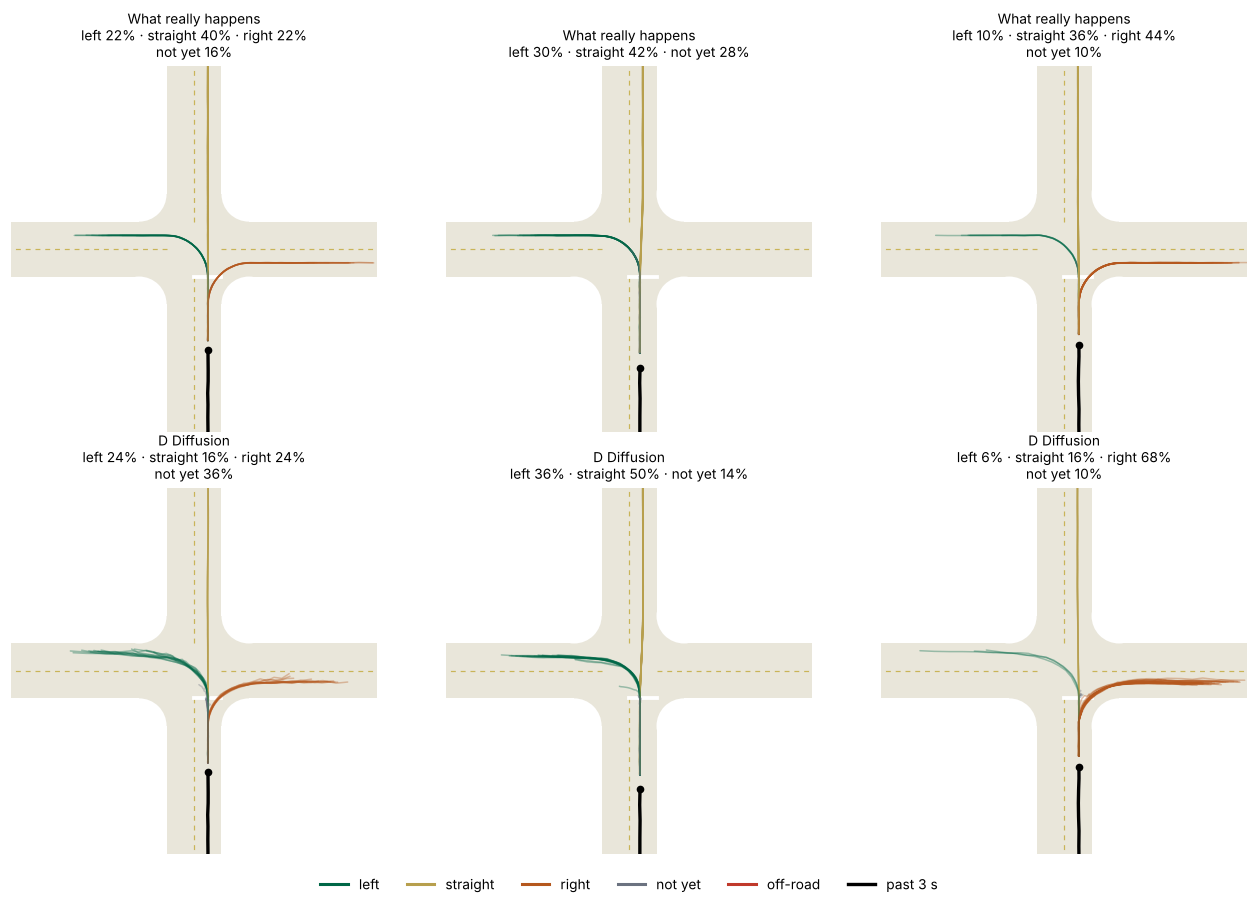

In [14]:
def alpha_bar(t):                      # cosine schedule: share of the clean answer left at noise level t
    return torch.cos((t + 0.008) / 1.008 * math.pi / 2).clamp(0, 1) ** 2

def time_features(t, d):
    f = torch.exp(torch.arange(d // 2) * (-math.log(1000.0) / (d // 2 - 1)))
    a = 1000 * t[:, None] * f[None]
    return torch.cat([a.sin(), a.cos()], 1)

class Diffusion(nn.Module):
    """D. Diffusion. The decoder sees the past (through cross-attention, like the translator),
    a NOISY copy of the whole future, and the noise level t. It outputs its best guess of the
    clean future. Loss: squared error, exactly the regression loss."""
    def __init__(self, mu, sd, d=64, layers=2, heads=4):
        super().__init__()
        self.enc = PastEncoder(d)
        self.register_buffer("mu", mu); self.register_buffer("sd", sd)
        self.inp = nn.Linear(2, d)
        self.pos = nn.Parameter(0.02 * torch.randn(N_FUT, d))
        self.temb = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d))
        layer = nn.TransformerDecoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.dec = nn.TransformerDecoder(layer, layers)
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 2))
        self.d = d

    def guess_clean(self, H, z, t):        # one pass of the decoder
        x = self.inp(z) + self.pos + self.temb(time_features(t, self.d))[:, None]
        return self.out(self.dec(x, H))

    def loss(self, pf, rel):
        H, _ = self.enc(pf)
        x0 = (rel - self.mu) / self.sd                       # standardised future
        t = torch.rand(x0.shape[0])
        ab = alpha_bar(t)[:, None, None]
        z = ab.sqrt() * x0 + (1 - ab).sqrt() * torch.randn_like(x0)
        return F.mse_loss(self.guess_clean(H, z, t), x0)

    @torch.no_grad()
    def sample(self, pf, k, steps=25, eta=1.0, keep=False):
        """Start from pure noise; at each step guess the clean future, then re-noise a little less.
        eta = 1 adds fresh noise every step; eta = 0 is the deterministic DDIM sampler."""
        H, _ = self.enc(pf)
        H = H.repeat_interleave(k, 0)
        B = H.shape[0]
        z = torch.randn(B, N_FUT, 2)
        drafts = []
        for i in range(steps, 0, -1):
            t, s = torch.full((B,), i / steps), torch.full((B,), (i - 1) / steps)
            x0 = self.guess_clean(H, z, t)
            if keep: drafts.append(x0 * self.sd + self.mu)
            if i == 1:
                z = x0; break
            ab_t, ab_s = alpha_bar(t)[:, None, None], alpha_bar(s)[:, None, None]
            eps = (z - ab_t.sqrt() * x0) / (1 - ab_t).sqrt()
            sig = eta * ((1 - ab_s) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_s).clamp(min=0).sqrt()
            z = ab_s.sqrt() * x0 + (1 - ab_s - sig ** 2).clamp(min=0).sqrt() * eps + sig * torch.randn_like(z)
        out = (z * self.sd + self.mu).view(-1, k, N_FUT, 2)
        return (out, torch.stack(drafts, 1).view(-1, k, steps, N_FUT, 2)) if keep else out

diff = fit("diff", lambda: Diffusion(rel_train.mean(0), rel_train.std(0)), rel_train)
DRAWN["D Diffusion"] = draw("diff", diff, te["past"], 20)[0]
report("D Diffusion", DRAWN["D Diffusion"])
look("D Diffusion", "diff", diff)

Diffusion's mix error is the lowest of the four (0.13; the VAE's 0.14 is within noise of it, and the perfect
model scores 0.11). It leaves the pavement least (0.2%) and has the best best-of-6 (1.63 m; the perfect
model, 1.51 m). It got
there with the regression kind of loss — squared error — on the coordinates themselves, with no
tokenizer.
Its price is the same as the translator's: 25 passes per future, 3.3 s per 1,000 futures.

## 9 · One pass of diffusion is a regression

Here is the claim from section 8, tested. Run the **same trained diffusion model** with 1, 2, 5,
10, 25 and 50 passes. With one pass, the decoder sees only pure noise, so its guess should be the
regression answer: the average future.

In [15]:
SWEEP = {}
for passes in (1, 2, 5, 10, 25, 50):
    smp, ms, _ = draw("diff", diff, te["past"], 20, steps=passes)
    SWEEP[passes] = r = scorecard(smp, te["fut"], ref)
    print(f"{passes:3d} passes  off-road {100 * r['offroad']:5.1f}%   mix error {r['mix_error']:.3f}   "
          f"best of 6 {r['min_ade6']:5.2f} m   one draw {r['ade_one']:5.2f} m   {ms:6.0f} ms per 1,000 futures")

one = draw("diff", diff, te["past"], 1, steps=1)[0][:, 0]
regf = draw("reg", reg, te["past"], 1)[0][:, 0]
print(f"\n1-pass diffusion vs regression: {np.linalg.norm(one - regf, axis=-1).mean():.2f} m apart on average "
      f"(vs {np.linalg.norm(one - te['fut'], axis=-1).mean():.2f} m from what the cars really did)")

  1 passes  off-road  20.6%   mix error 0.477   best of 6  4.88 m   one draw  5.54 m      142 ms per 1,000 futures


  2 passes  off-road   4.0%   mix error 0.242   best of 6  3.11 m   one draw  5.47 m      276 ms per 1,000 futures


  5 passes  off-road   0.5%   mix error 0.155   best of 6  2.02 m   one draw  5.95 m      696 ms per 1,000 futures


 10 passes  off-road   0.3%   mix error 0.138   best of 6  1.76 m   one draw  6.28 m     1385 ms per 1,000 futures


 25 passes  off-road   0.2%   mix error 0.133   best of 6  1.63 m   one draw  6.49 m     3480 ms per 1,000 futures


 50 passes  off-road   0.3%   mix error 0.134   best of 6  1.55 m   one draw  6.47 m     6736 ms per 1,000 futures

1-pass diffusion vs regression: 0.73 m apart on average (vs 5.55 m from what the cars really did)


**What you should see.** With one pass, diffusion behaves like regression: 21% of its futures leave
the pavement (regression: 22%), and its mix error is 0.48 (regression: 0.53). Its one answer
sits about 0.7 m from the regression answer, much closer than either is to what the cars really did
(about 5.5 m). Two passes already cut off-road futures to 4%; five passes to 0.5%.
After about 10 passes the mix and the off-road share stop moving. Best-of-6 keeps improving slowly
(1.76 m at 10 passes, 1.63 m at 25, 1.55 m at 50), and every doubling of passes doubles the time.

The picture below runs the sampler on the first ambiguous past and keeps each pass's guess of the
clean future. Watch the early guesses huddle around the average, then split onto real branches.

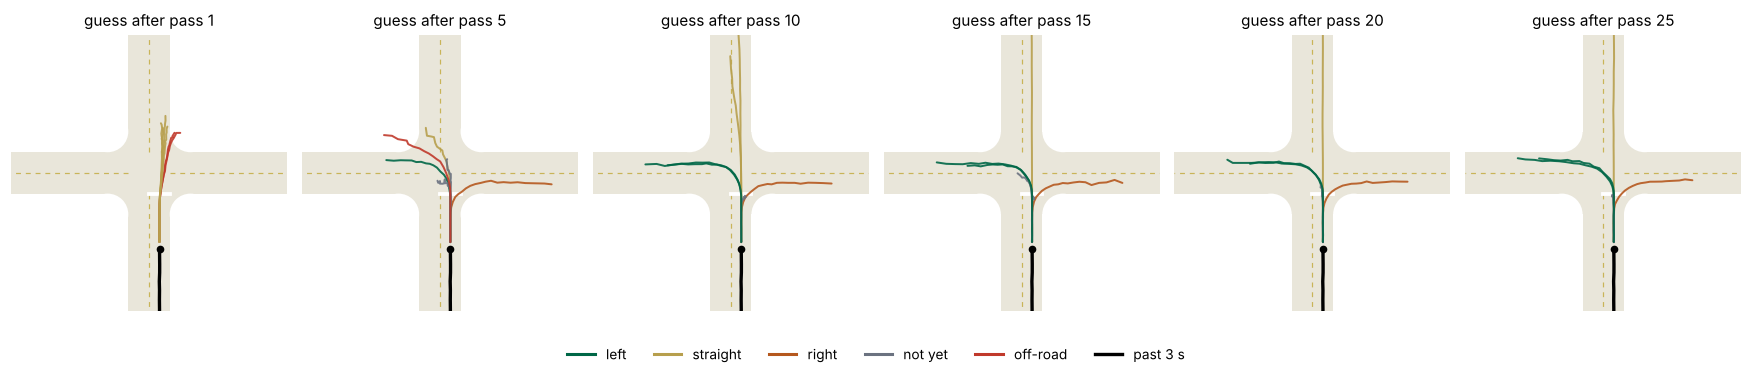

In [16]:
torch.manual_seed(3)
past1 = te["past"][CASES[0]:CASES[0] + 1]
_, drafts = diff.sample(past_features(past1), 6, steps=25, keep=True)
drafts = from_rel(past1, drafts[0].numpy().reshape(1, -1, N_FUT, 2)).reshape(6, 25, N_FUT, 2)
fig, axs = plt.subplots(1, 6, figsize=(16, 3.4))
for ax, p in zip(axs, [1, 5, 10, 15, 20, 25]):
    plot_paths(ax, drafts[:, p - 1], past1[0], lim=24, alpha=0.9, lw=1.3)
    ax.set_title(f"guess after pass {p}")
plt.tight_layout(rect=(0, 0.08, 1, 1)); legend_classes(fig, 0.0); plt.show()

## 10 · The scorecard

All six rows were computed on the same 1,000 test pasts, with 20 draws each.

In [17]:
order = ["Constant velocity", "A Regression", "B Cond. VAE", "C Translator", "D Diffusion", "Perfect model"]
print(f"{'':18s}{'off-road':>10s}{'mix error':>11s}{'best of 6':>11s}{'one draw':>10s}")
for k in order:
    r = RESULTS[k]
    print(f"{k:18s}{100 * r['offroad']:9.1f}%{r['mix_error']:11.3f}{r['min_ade6']:9.2f} m{r['ade_one']:8.2f} m")

                    off-road  mix error  best of 6  one draw
Constant velocity       0.0%      0.505     6.59 m    6.59 m
A Regression           22.5%      0.532     5.48 m    5.48 m
B Cond. VAE             2.3%      0.143     1.70 m    6.09 m
C Translator            0.8%      0.164     1.67 m    7.11 m
D Diffusion             0.2%      0.133     1.63 m    6.49 m
Perfect model           0.0%      0.111     1.51 m    6.53 m


Your numbers will differ a little from these (different CPU, different thread count), but the
order should not. From the run that built this lab:

| model | off-road | mix error | best of 6 | one draw | passes per future | time per 1,000 futures |
|---|---|---|---|---|---|---|
| Constant velocity | 0.0% | 0.505 | 6.59 m | 6.59 m | 0 (no network) | — |
| A Regression | 22.5% | 0.532 | 5.48 m | 5.48 m | 1 | 2 ms |
| B Cond. VAE | 2.3% | 0.143 | 1.70 m | 6.09 m | 1 | 3 ms |
| C Translator | 0.8% | 0.164 | 1.67 m | 7.11 m | 25 | 1.9 s |
| D Diffusion | 0.2% | 0.133 | 1.63 m | 6.49 m | 25 | 3.3 s |
| Perfect model | 0.0% | 0.111 | 1.51 m | 6.53 m | — | — |

Three things to take away.

1. **The one-draw score is won by regression, because it predicts the average.** When futures
   differ, that score rewards impossible paths. Read best-of-6 together with the mix error.
2. **All three generative models beat regression by a wide margin**, on the mix and on
   best-of-6. Among the three, the gaps are small. Each model was trained once, so treat mix
   gaps of about 0.01 as a tie: diffusion (0.133) and the tuned VAE (0.143) tie on the mix.
   The clear difference is staying on the road: the VAE's futures leave the pavement about
   10 times as often as diffusion's. The translator is in between on off-road and best-of-6,
   and last of the three on the mix.
3. **The price is passes, and the cost of each pass.** Diffusion and the translator need 25
   passes per future: about 2 s (translator) and 3 s (diffusion) per 1,000 futures here, against
   1 to 3 ms for regression or the VAE. Each diffusion pass also costs more than the VAE's one
   pass (133 ms against 3 ms per 1,000), because its decoder is a transformer, not a small MLP.

So the honest claim is not "diffusion is always more accurate". It is narrower: **from the same
paired data and the same kind of loss as regression, diffusion draws futures that almost never
leave the road, with a mix as good as the best alternative, and you pay for it in passes.**
Whether that is worth it depends on the job (section 13).

## 11 · Before you trust this result

**The baseline.** Constant velocity, the classical forecast, plus a perfect model that shows the
floor. All three generative models beat constant velocity by a wide margin on the mix and on
best-of-6. Regression does not beat it on the mix. On the mix, diffusion and the tuned VAE come
closest to the floor; diffusion is closest on staying on the road and on best-of-6.

**The split, and why it is honest.** Training, validation and test cars come from different random
seeds, so no test car — and no test driver's decision — was seen in training. The VAE's one
setting (σ) was chosen on the validation cars, never on the test cars. Every trained model got the
same budget: 6,000 steps of 256 cars.

**The ugly cases.**
- *It is one simulated intersection.* The drivers follow a logit rule we wrote. Real drivers have
  turn signals, gaps in opposing traffic, pedestrians and bad days. A model this small, on real
  data, would need far more than 20,000 trajectories.
- *Every model blurs a hard rule.* A right turn is impossible if it would need braking harder
  than 4.5 m/s². For the 41 test cars close to that limit, diffusion's mix error is 0.20, against
  0.13 elsewhere (the perfect model: 0.14 and 0.11). The VAE and the translator do no better
  (0.20 and 0.21). Learned models turn a hard physical limit into a soft one; if your
  application lives at such a limit, check it there. The cell below recomputes these numbers.
- *The mix error cannot go below about 0.11*, because 20 draws is a small sample.
  Each model was trained once, so treat gaps of about 0.01 as a tie.
- *Diffusion and the translator cost 25 network passes per future*, against 1 for regression.
  At a roadside unit, that is a real price.
- *"Best of 6" flatters any model that spreads its draws widely.* That is why it is read together
  with the mix error, which punishes spreading draws where drivers do not go.

In [18]:
margin = te["state"]["v_a"] ** 2 - 3.5 ** 2 - 2 * A_MAX * (te["state"]["D0"] - LANE)   # <= 0: a right turn is possible
near = np.abs(margin) < 3
print(f"{near.sum()} test cars within reach of the right-turn braking limit")
for name, smp in [("Perfect model", REF["test"]["oracle"])] + [(k, DRAWN[k]) for k in ("B Cond. VAE", "C Translator", "D Diffusion")]:
    e = 0.5 * np.abs(class_shares(smp) - ref).sum(1)
    print(f"{name:14s} mix error near the limit {e[near].mean():.2f}   elsewhere {e[~near].mean():.2f}")

41 test cars within reach of the right-turn braking limit
Perfect model  mix error near the limit 0.14   elsewhere 0.11
B Cond. VAE    mix error near the limit 0.20   elsewhere 0.14
C Translator   mix error near the limit 0.21   elsewhere 0.16
D Diffusion    mix error near the limit 0.20   elsewhere 0.13


## 12 · Stretch (optional, about 8 minutes): 500 cars instead of 20,000

The unCLIP crash run in section 4.11 found a diffusion prior that gave **the same answer for every noise
seed**: with one sketch per narrative, it had learned a regression, not a distribution. Can you
make that happen here? Train the same diffusion model on only the first 500 training cars.

In [19]:
torch.manual_seed(0)
small = Diffusion(rel_train[:500].mean(0), rel_train[:500].std(0))
train(small, pf_train[:500], rel_train[:500], STEPS["diff"], log_every=2000)
s_test = draw("diff", small, te["past"], 20)[0]
report("D on 500 cars", s_test)
own = draw("diff", small, tr["past"][:500], 8)[0]                 # 8 draws on each of its 500 training pasts
big = draw("diff", diff, tr["past"][:500], 8)[0]                   # the full model on the same pasts
spread = lambda s: np.linalg.norm(s[:, :, None] - s[:, None], axis=-1).mean(-1).sum((1, 2)).mean() / 56
print(f"on its 500 training pasts: its 8 draws sit {100 * spread(own):.1f} cm apart (full model: {spread(big):.2f} m), "
      f"and {np.median(np.linalg.norm(own - tr['fut'][:500, None], axis=-1).mean(-1)):.2f} m from each car's own future")

  step  2000   loss 0.1008     155 s


  step  4000   loss 0.0089     314 s


  step  6000   loss 0.0026     476 s


D on 500 cars     off-road   7.8%   mix error 0.500   best of 6  6.25 m   one draw  6.26 m


on its 500 training pasts: its 8 draws sit 1.4 cm apart (full model: 6.36 m), and 0.18 m from each car's own future


**What happened in the run that built this lab.** Trained on 500 cars, diffusion's mix error on
the test cars rose to 0.50, no better than regression (0.53), and 8% of its futures left the
pavement. On the 500 pasts it was trained on, its 8 draws per past sat 1.4 cm apart and about
0.18 m from that car's own training future. The full model, on the same 500 pasts, spreads
its draws 6.4 m apart.

That is the unCLIP crash result again. With one future per past and few pasts, the cheapest way
to make the loss small is to remember each car's future. **A diffusion model can only learn a
spread that is in the data:** it needs many similar pasts with different outcomes.

## 13 · Which one when

| if you need… | use | because |
|---|---|---|
| one best guess, fast (a dashboard ETA, the next second) | regression | it *is* the best single guess under squared error, at one pass |
| several plausible futures, a mix you can trust | diffusion or a translator | they keep the modes; diffusion works on raw numbers, the translator needs a tokenizer |
| futures in one pass, and you can live with some blur | conditional VAE | cheap to sample, but z must carry all the variety |
| to fix part of the answer (a known destination, observed detector readings) and fill in the rest | diffusion | you can paste known values into the draft at every pass, with no retraining (sections 4.10 and 4.13 show it on detector data) |

```text
Fit card — Diffusion for trajectory forecasting
Idea in one sentence:  Train a decoder to clean up noisy copies of the future given the past;
                       generate by cleaning up pure noise in small steps.
Why it works:          In the last passes the draft has already picked one branch, so the
                       average each pass returns is a real path, not a blend.
Fits these tasks:      Forecasts with several plausible outcomes, scenario generation,
                       gap filling (generation, prediction).
Needs this data:       Paired (past, future) trajectories; thousands or more; many similar pasts
                       with different outcomes; no labels. Drone video, connected-vehicle data.
Breaks when:           There are too few similar pasts (it memorises them, section 12); the pass
                       budget is tight; the pasts are unlike anything in training; a hard
                       physical limit matters (it gets blurred, section 11).
Keep the classical method when:  One best guess is all you need, or the outcome is nearly certain
                       (a freeway car 1 s ahead) — constant velocity or regression is cheaper.
```

## 14 · Check yourself

1. A TMC dashboard shows the expected travel time on a corridor 15 minutes ahead. Regression or
   diffusion? What would diffusion add, and would anyone use it?
2. You have two years of drone video at one intersection, and you want 1,000 left-turn conflicts
   to test a warning system. Which of today's models would you train, on what pairs, and how
   would you check that the conflicts it generates are ones that could really happen?
3. A paper reports that its model has the lowest ADE on a trajectory benchmark. After today,
   what is the first question you would ask?
4. You have 207 crash narratives, each with one sketch. What will a diffusion model trained to
   draw the sketch from the narrative learn, and why? What data would change that?
5. In section 9, two passes already removed most off-road futures. Why might a real-time
   system still use 10 or more?

**Further reading.** Sections 4.10 (diffusion basics), 4.11 (unCLIP) and 4.12 (diffusion in the
literature, with its 35-paper companion) on the course site. MotionDiffuser (Jiang et al., CVPR
2023) makes diffusion forecasts; MotionLM (Seff et al., ICCV 2023) takes the translator approach at
Waymo scale.